# Saltshield — Análisis de prima para préstamos cripto (BTC, 2021→actualidad)

Este notebook calcula la prima necesaria para un servicio tipo **Saltshield**: el cliente paga una prima para cubrir posibles liquidaciones de un préstamo con LTV inicial 50% y plazo 1 año.
Se documenta cada paso y se guardan resultados y gráficos en `prestamos/analysis_plots/`.

## Resumen del enfoque
- Convertimos la serie minutal a cierre diario para eficiencia.
- Para cada fecha de inicio `t0` desde 2021 tal que existe `t0 + 365d`, calculamos `p0` (precio en `t0`) y `pT` (precio en `t0+365d`).
- Definimos liquidación si `pT < INIT_LTV * p0` (con INIT_LTV = 0.50 por defecto y LTV_liq = 1.0 al vencimiento).
- Calculamos pérdida por préstamo `loss = max(0, P - c0 * pT)` y su fracción sobre `P`.
- Estimamos prima break-even = `E[loss]/P` y primas con margen (10/20/30%).

In [ ]:
# Imports y parámetros
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import json

DATA_PATH = Path('/Users/alexis/Documents/Deep_dive/btcusd_bitstamp_1min_2012-2025.csv')
OUT_DIR = Path('prestamos/analysis_plots')
OUT_DIR.mkdir(parents=True, exist_ok=True)

START_DATE = pd.Timestamp('2021-01-01', tz='UTC')
HORIZON_DAYS = 365
INIT_LTV = 0.50  # LTV inicial del préstamo
LIQ_LTV = 1.0    # LTV al vencimiento que fuerza liquidación
PRINCIPAL_USD = 10_000

print('CSV exists?', DATA_PATH.exists())

CSV exists? True


## Carga eficiente y resample diario
Leemos únicamente `timestamp` y `close` en chunks, convertimos `timestamp` (epoch s) a `datetime` UTC y tomamos el cierre diario (`.resample('D').last()`).

In [ ]:
# Leer en chunks y construir serie diaria
usecols = ['timestamp','close']
reader = pd.read_csv(DATA_PATH, usecols=usecols, chunksize=2_000_000)
parts = []
for i, chunk in enumerate(reader):
    chunk['date'] = pd.to_datetime(chunk['timestamp'].astype(int), unit='s', utc=True)
    parts.append(chunk[['date','close']])
    print(f'read chunk {i+1}, rows {len(chunk)}')

price_min = pd.concat(parts).set_index('date').sort_index()
price_daily = price_min['close'].resample('D').last().dropna()
print('daily len total:', len(price_daily))
price_daily = price_daily.loc[START_DATE:]
last_date = price_daily.index.max()
print('daily range after filter:', price_daily.index.min(), '->', last_date)

read chunk 1, rows 2000000
read chunk 2, rows 2000000
read chunk 2, rows 2000000
read chunk 3, rows 2000000
read chunk 4, rows 846600
read chunk 3, rows 2000000
read chunk 4, rows 846600
daily len total: 4756
daily range after filter: 2021-01-01 00:00:00+00:00 -> 2025-01-07 00:00:00+00:00
daily len total: 4756
daily range after filter: 2021-01-01 00:00:00+00:00 -> 2025-01-07 00:00:00+00:00


## Escenarios a 1 año y cálculo de pérdidas
Vectorizamos la construcción de `p0` y `pT` para todas las fechas de inicio posibles y calculamos la pérdida por préstamo.

In [ ]:
horizon = pd.Timedelta(days=HORIZON_DAYS)
start_dates = price_daily.index[price_daily.index + horizon <= last_date]
print('Start dates available:', len(start_dates))
p0 = price_daily.reindex(start_dates).values
end_dates = start_dates + horizon
pT = price_daily.reindex(end_dates).values
res = pd.DataFrame({'start': start_dates, 'p0': p0, 'pT': pT})
res = res.dropna()
print('Rows with full horizon:', len(res))

# Determine liquidations and losses
thresholds = INIT_LTV * res['p0']  # pT must be >= this to avoid LTV>=1.0
res['liquidated'] = (res['pT'] < thresholds)
res['loss_frac'] = np.maximum(0.0, 1.0 - res['pT'] / thresholds)
res['loss_usd'] = res['loss_frac'] * PRINCIPAL_USD

n = len(res)
n_liq = int(res['liquidated'].sum())
freq_liq = n_liq / n if n>0 else 0.0
mean_loss_given_liq = res.loc[res['liquidated'], 'loss_frac'].mean() if n_liq>0 else 0.0
expected_loss_frac = res['loss_frac'].mean()
expected_loss_usd = expected_loss_frac * PRINCIPAL_USD

print(f'Num starts: {n}, Num liquidations: {n_liq}, P(liq) = {freq_liq:.6f}')
print(f'Mean loss (given liq) [fraction of P]: {mean_loss_given_liq:.6f}')
print(f'Expected loss per loan (fraction of P): {expected_loss_frac:.6f}')
print(f'Expected loss per loan (USD, P={PRINCIPAL_USD}): ${expected_loss_usd:,.2f}')

Start dates available: 1103
Rows with full horizon: 1103
Num starts: 1103, Num liquidations: 155, P(liq) = 0.140526
Mean loss (given liq) [fraction of P]: 0.263544
Expected loss per loan (fraction of P): 0.037035
Expected loss per loan (USD, P=10000): $370.35


## Primas (break-even y con margen)
Calculamos la prima de break-even = `expected_loss_frac` y primas para márgenes 10%, 20% y 30%.

In [ ]:
margins = [0.0, 0.10, 0.20, 0.30]
premiums = {m: expected_loss_frac * (1.0 + m) for m in margins}
for m, p in premiums.items():
    print(f'margin {int(m*100)}% -> premium = {p*100:.4f}% of principal -> ${p*PRINCIPAL_USD:,.2f} for P={PRINCIPAL_USD}')
# Save summary JSON
summary = {
    'n_starts': int(n),
    'n_liq': int(n_liq),
    'p_liq': float(freq_liq),
    'mean_loss_given_liq_frac': float(mean_loss_given_liq),
    'expected_loss_frac': float(expected_loss_frac),
    'expected_loss_usd': float(expected_loss_usd),
    'premiums_frac': {str(int(m*100)): float(p) for m,p in premiums.items()}
}
with open(OUT_DIR / 'saltshield_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)
print('Wrote summary to', OUT_DIR / 'saltshield_summary.json')

margin 0% -> premium = 3.7035% of principal -> $370.35 for P=10000
margin 10% -> premium = 4.0738% of principal -> $407.38 for P=10000
margin 20% -> premium = 4.4442% of principal -> $444.42 for P=10000
margin 30% -> premium = 4.8145% of principal -> $481.45 for P=10000
Wrote summary to prestamos/analysis_plots/saltshield_summary.json


## Visualizaciones
Histogramas de `p_T/p0` y de la fracción de pérdida (solo liquidaciones).

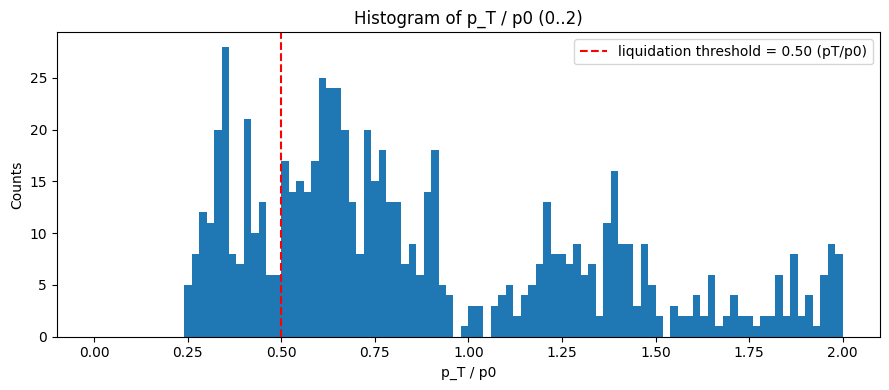

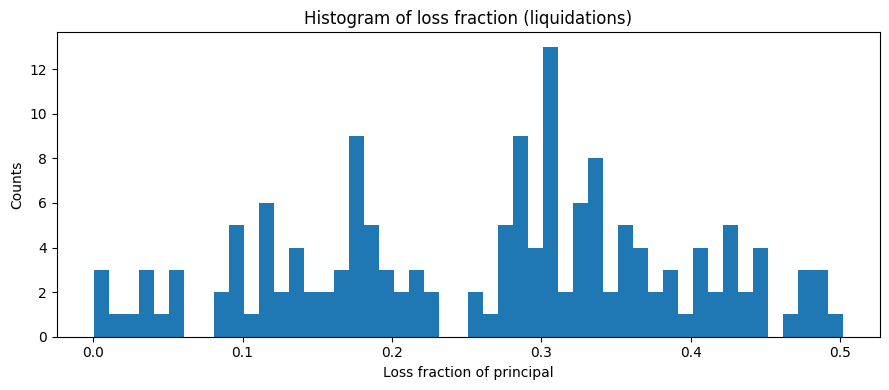

In [ ]:
ratio = res['pT'] / res['p0']
plt.figure(figsize=(9,4))
plt.hist(ratio, bins=100, range=(0,2))
plt.axvline(INIT_LTV, color='r', linestyle='--', label=f'liquidation threshold = {INIT_LTV:.2f} (pT/p0)')
plt.title('Histogram of p_T / p0 (0..2)')
plt.xlabel('p_T / p0')
plt.ylabel('Counts')
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'ratio_pT_p0_hist.png')
plt.show()

plt.figure(figsize=(9,4))
plt.hist(res['loss_frac'][res['loss_frac']>0], bins=50)
plt.title('Histogram of loss fraction (liquidations)')
plt.xlabel('Loss fraction of principal')
plt.ylabel('Counts')
plt.tight_layout()
plt.savefig(OUT_DIR / 'loss_frac_hist.png')
plt.show()

# Save detailed CSV per start date
res.to_csv(OUT_DIR / 'saltshield_results_by_start.csv', index=False)


## Conclusiones rápidas
- La `expected_loss_frac` es la prima break-even por préstamo; multiplicándola por (1+margin) se obtienen primas con margen de beneficio.
- Recomendaciones: evaluar reducir LTV inicial o exigir top-ups, usar monitoring intradía y considerar modelado estocástico para cola extrema.

In [ ]:
# Código: cargar resultados, calcular percentiles, CDF, scatter y top losses
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT_DIR = Path('prestamos/analysis_plots')
# si no está res en memoria, intentar cargar CSVes ya generados
try:
    res
except NameError:
    csv_path = OUT_DIR / 'saltshield_results_by_start.csv'
    if csv_path.exists():
        res = pd.read_csv(csv_path, parse_dates=['start'])
        print('Loaded results from', csv_path)
    else:
        # Intentar también cargar minute-level por defecto si existe
        csv_min = OUT_DIR / 'saltshield_results_by_start_minute.csv'
        if csv_min.exists():
            res = pd.read_csv(csv_min, parse_dates=['start'])
            print('Loaded minute results from', csv_min)
        else:
            raise FileNotFoundError(f"No se encontró {csv_path} ni {csv_min}. Ejecuta primero la celda que genera 'res' o corre run_saltshield.py / run_saltshield_minute.py")

# cargar yearly si existe
yearly = None
yy_path = OUT_DIR / 'saltshield_yearly_summary.csv'
if yy_path.exists():
    yearly = pd.read_csv(yy_path)
else:
    yy_min = OUT_DIR / 'saltshield_yearly_summary_minute.csv'
    if yy_min.exists():
        yearly = pd.read_csv(yy_min)

# Percentiles y metrics
total_starts = len(res)
liquidations = res['loss_frac'] > 0
n_liq = liquidations.sum()

percentiles = [0.5, 0.75, 0.9, 0.95, 0.99]
loss_frac_pct = {int(p*100): float(res['loss_frac'].quantile(p)) for p in percentiles}
loss_usd_pct = {int(p*100): float(res['loss_usd'].quantile(p)) for p in percentiles}

var95 = loss_frac_pct[95]
es95 = float(res.loc[res['loss_frac'] >= var95, 'loss_frac'].mean())

print(f"Total starts: {total_starts}")
print(f"Total liquidations: {int(n_liq)} (rate {n_liq/total_starts:.3%})")
print('\nPercentiles (loss fraction of principal):')
for p, v in loss_frac_pct.items():
    try:
        print(f'  p{p}: {v:.4f} fraction -> ${v*PRINCIPAL_USD:,.2f}')
    except NameError:
        print(f'  p{p}: {v:.4f} fraction')
print(f"\nVaR95 fraction: {var95:.4f} -> ${var95*PRINCIPAL_USD:,.2f}" if 'PRINCIPAL_USD' in globals() else f"\nVaR95 fraction: {var95:.4f}")
print(f"ES95 fraction: {es95:.4f} -> ${es95*PRINCIPAL_USD:,.2f}" if 'PRINCIPAL_USD' in globals() else f"ES95 fraction: {es95:.4f}")

# Top 10 losses (handle missing columns gracefully)
res['start'] = pd.to_datetime(res['start'])
available_cols = [c for c in ['start','p0','pT','loss_usd','loss_frac','ltv_end'] if c in res.columns]
top10 = res.sort_values('loss_usd', ascending=False).head(10)[available_cols]
print('\nTop 10 losses (rows):')
print(top10.to_string(index=False))

# Guardar resumen adicional
add_summary = {
    'total_starts': int(total_starts),
    'n_liquidations': int(n_liq),
    'loss_frac_percentiles': loss_frac_pct,
    'loss_usd_percentiles': loss_usd_pct,
    'var95_frac': var95,
    'es95_frac': es95
}
with open(OUT_DIR / 'saltshield_additional_summary.json', 'w') as f:
    json.dump(add_summary, f, indent=2)
print('\nSaved additional summary JSON to', OUT_DIR / 'saltshield_additional_summary.json')

# Gráficos: CDF, scatter y anual si yearly
plt.figure(figsize=(8,4))
vals = np.sort(res['loss_frac'].values)
cdf = np.arange(len(vals))/float(len(vals))
plt.plot(vals, cdf)
plt.xlabel('Loss fraction of principal')
plt.ylabel('CDF')
plt.title('CDF of loss fraction (all starts)')
plt.tight_layout()
plt.savefig(OUT_DIR / 'loss_frac_cdf_additional.png')
plt.show()

# Scatter loss vs p0 (liquidations only)
liq = res[res['loss_frac']>0]
if len(liq)>0:
    plt.figure(figsize=(8,5))
    plt.scatter(liq['p0'], liq['loss_usd'], alpha=0.7, s=20)
    plt.xscale('log')
    plt.xlabel('p0 (log scale)')
    plt.ylabel('Loss (USD)')
    plt.title('Loss (USD) vs Price at origin p0 (liquidations only)')
    plt.tight_layout()
    plt.savefig(OUT_DIR / 'loss_vs_p0_scatter_additional.png')
    plt.show()

# Annual bar chart si yearly cargado
if yearly is not None:
    plt.figure(figsize=(8,4))
    if 'start_year' in yearly.columns:
        plt.bar(yearly['start_year'].astype(str), yearly['p_liq']*100, color='C2')
    else:
        plt.bar(yearly['start_year'].astype(str), yearly['p_liq']*100, color='C2')
    plt.ylabel('% of starts that liquidated')
    plt.xlabel('Start year')
    plt.title('Annual liquidation rate (by start year)')
    plt.tight_layout()
    plt.savefig(OUT_DIR / 'annual_liquidation_rate_additional.png')
    plt.show()

print('\nPlots saved to', OUT_DIR)


### Interpretación y recomendaciones ampliadas

- **Qué significa cada métrica:**
  - `P(liq)` o tasa de liquidación: probabilidad histórica de que un préstamo originado en `t0` acabe con LTV≥100% a 1 año.
  - `Mean loss given liq`: fracción promedio del principal perdida si ocurre la liquidación (excluye los casos sin liquidación).
  - `Expected loss`: promedio incondicional de pérdida por préstamo (es la prima break-even en % del principal).

  - Considerar calcular primas adaptadas por año de origen: 2021 muestra mucho más riesgo histórico que 2023, por ejemplo.

In [ ]:
# Carga rápida de resultados minuto con fricción (slippage+fees) y resumen
from pathlib import Path
import pandas as pd
OUT_DIR = Path('/Users/alexis/Documents/Deep_dive/prestamos/analysis_plots')
# Preferir CSV con fricción si existe
csv_fric = OUT_DIR / 'saltshield_results_by_start_minute_friction_s1_f5.csv'
csv_min = OUT_DIR / 'saltshield_results_by_start_minute.csv'
if csv_fric.exists():
    df = pd.read_csv(csv_fric, parse_dates=['start'])
    print('Loaded friction-adjusted minute CSV:', csv_fric)
elif csv_min.exists():
    df = pd.read_csv(csv_min, parse_dates=['start'])
    print('Loaded minute CSV (no friction):', csv_min)
else:
    raise FileNotFoundError('No minute-level CSV found. Run run_saltshield_minute.py first')

print('Rows loaded:', len(df))
print('Sample rows:')
print(df.head().to_string(index=False))

# Quick aggregates
n = len(df)
if 'loss_usd_friction' in df.columns:
    expected_loss_usd = df['loss_usd_friction'].mean()
    p_liq = (df['loss_usd_friction']>0).mean()
else:
    expected_loss_usd = df['loss_usd'].mean()
    p_liq = (df['loss_usd']>0).mean()
print('\nExpected loss per loan (USD):', f'${expected_loss_usd:,.2f}')
print('Empirical P(liq):', f'{p_liq:.4%}')

print('\nLos archivos gráficos y JSON con fricción están en', OUT_DIR)


In [ ]:
# Sensibilidad: inicios horarios (stride_minutes=60) y comparación con diario/minuto
from pathlib import Path
import pandas as pd
import numpy as np
OUT_DIR = Path('prestamos/analysis_plots')

# Prefer minute CSV (must exist from earlier runs)
csv_min = OUT_DIR / 'saltshield_results_by_start_minute.csv'
csv_daily = OUT_DIR / 'saltshield_results_by_start.csv'

if not csv_min.exists() and not csv_daily.exists():
    raise FileNotFoundError('No minute or daily CSVs found. Ejecuta run_saltshield_minute.py o run_saltshield.py primero')

results = {}

# Minute-level summary (if available)
if csv_min.exists():
    df_min = pd.read_csv(csv_min, parse_dates=['start'])
    results['minute'] = {
        'n_starts': len(df_min),
        'n_liq': int((df_min['loss_usd']>0).sum()),
        'p_liq': float((df_min['loss_usd']>0).mean()),
        'expected_loss_usd': float(df_min['loss_usd'].mean())
    }
    print('Minute-level: starts', results['minute']['n_starts'], 'P(liq)', results['minute']['p_liq'])

# Hourly starts: take minute CSV and filter start times at minute=0 (UTC)
if csv_min.exists():
    df_min['start'] = pd.to_datetime(df_min['start'], utc=True)
    df_hour = df_min[df_min['start'].dt.minute == 0].copy()
    results['hourly'] = {
        'n_starts': len(df_hour),
        'n_liq': int((df_hour['loss_usd']>0).sum()),
        'p_liq': float((df_hour['loss_usd']>0).mean()),
        'expected_loss_usd': float(df_hour['loss_usd'].mean())
    }
    print('Hourly-level: starts', results['hourly']['n_starts'], 'P(liq)', results['hourly']['p_liq'])

# Daily-level (if available)
if csv_daily.exists():
    df_daily = pd.read_csv(csv_daily, parse_dates=['start'])
    results['daily'] = {
        'n_starts': len(df_daily),
        'n_liq': int((df_daily['loss_usd']>0).sum()),
        'p_liq': float((df_daily['loss_usd']>0).mean()),
        'expected_loss_usd': float(df_daily['loss_usd'].mean())
    }
    print('Daily-level: starts', results['daily']['n_starts'], 'P(liq)', results['daily']['p_liq'])

# Save comparison
import json
with open(OUT_DIR / 'saltshield_granularity_comparison.json', 'w') as f:
    json.dump(results, f, indent=2)
print('Saved granularity comparison JSON to', OUT_DIR / 'saltshield_granularity_comparison.json')

# Print concise table
from pprint import pprint
pprint(results)


In [ ]:
# Monte Carlo bootstrap de retornos diarios para estimar cola extrema (1-year horizon)
# Esta celda simula N paths muestreando retornos diarios con reemplazo desde la serie histórica.
import numpy as np
import pandas as pd
from pathlib import Path
import json
OUT_DIR = Path('prestamos/analysis_plots')

# Configurables
N_SIM = 20000  # número de simulaciones; bajar a 5000 si quieres rapidez
HORIZON_DAYS = 365
RECOVER_FACTOR = 1.0  # multiplicador de recuperación; si quieres incluir fricción pon 0.985 por ejemplo

# Obtener serie diaria de returns: usar price_daily si está en memoria, sino reconstruir
try:
    price_daily
except NameError:
    # intento de cargar desde el CSV fuente de minutos y resamplear
    DATA_PATH = Path('/Users/alexis/Documents/Deep_dive/btcusd_bitstamp_1min_2012-2025.csv')
    if not DATA_PATH.exists():
        raise FileNotFoundError('DATA_PATH not found to build price_daily for Monte Carlo')
    print('Rebuilding daily series from CSV (may be slow)...')
    usecols = ['timestamp','close']
    reader = pd.read_csv(DATA_PATH, usecols=usecols, chunksize=2_000_000)
    parts = []
    for chunk in reader:
        chunk['date'] = pd.to_datetime(chunk['timestamp'].astype(int), unit='s', utc=True)
        parts.append(chunk[['date','close']])
    price_min = pd.concat(parts).set_index('date').sort_index()
    price_daily = price_min['close'].resample('D').last().dropna()

# Compute daily log returns
returns = np.log(price_daily).diff().dropna()
print('Using historical daily returns count =', len(returns))

# bootstrap simulation: sample with replacement blocks of daily returns of length HORIZON_DAYS
# vectorized approach: sample an array of shape (N_SIM, HORIZON_DAYS)
idx = np.random.randint(0, len(returns), size=(N_SIM, HORIZON_DAYS))
sampled = returns.values[idx]
# sum log-returns along horizon
cum_log_returns = sampled.sum(axis=1)
R = np.exp(cum_log_returns)  # pT / p0

# include recovery factor (slippage+fees) if desired
R_eff = R * RECOVER_FACTOR

INIT_LTV = 0.50
# loss fraction as before: loss_frac = max(0, 1 - R/INIT_LTV)
loss_frac = np.maximum(0.0, 1.0 - R / INIT_LTV)
loss_frac_eff = np.maximum(0.0, 1.0 - R_eff / INIT_LTV)

p_liq_mc = float((R < INIT_LTV).mean())
mean_loss_given_liq_mc = float(loss_frac[R < INIT_LTV].mean()) if (R < INIT_LTV).any() else 0.0
expected_loss_frac_mc = float(loss_frac.mean())
expected_loss_usd_mc = expected_loss_frac_mc * PRINCIPAL_USD if 'PRINCIPAL_USD' in globals() else None

print('Monte Carlo (bootstrap) results:')
print('N_SIM =', N_SIM)
print('P(liq) MC:', p_liq_mc)
print('Mean loss given liq MC (fraction):', mean_loss_given_liq_mc)
print('Expected loss per loan (MC, fraction):', expected_loss_frac_mc)
if expected_loss_usd_mc is not None:
    print('Expected loss per loan (MC, USD):', f'${expected_loss_usd_mc:,.2f}')

# With friction (effective R)
p_liq_mc_eff = float((R_eff < INIT_LTV).mean())
expected_loss_frac_mc_eff = float(loss_frac_eff.mean())
expected_loss_usd_mc_eff = expected_loss_frac_mc_eff * PRINCIPAL_USD if 'PRINCIPAL_USD' in globals() else None
print('\nWith RECOVER_FACTOR =', RECOVER_FACTOR)
print('P(liq) MC (eff):', p_liq_mc_eff)
print('Expected loss per loan (MC, fraction, eff):', expected_loss_frac_mc_eff)
if expected_loss_usd_mc_eff is not None:
    print('Expected loss per loan (MC, USD, eff):', f'${expected_loss_usd_mc_eff:,.2f}')

# Save MC summary
d = {
    'N_SIM': int(N_SIM),
    'p_liq_mc': p_liq_mc,
    'mean_loss_given_liq_mc': mean_loss_given_liq_mc,
    'expected_loss_frac_mc': expected_loss_frac_mc,
    'expected_loss_usd_mc': expected_loss_usd_mc,
    'recover_factor': RECOVER_FACTOR,
    'p_liq_mc_eff': p_liq_mc_eff,
    'expected_loss_frac_mc_eff': expected_loss_frac_mc_eff,
    'expected_loss_usd_mc_eff': expected_loss_usd_mc_eff
}
with open(OUT_DIR / 'saltshield_mc_summary.json', 'w') as f:
    json.dump(d, f, indent=2)
print('Saved Monte Carlo summary to', OUT_DIR / 'saltshield_mc_summary.json')
